# Aprendizado Supervisionado: Classificação e Regressão

**Aluna:** Layse Steffany Pereira de Souza · UDF · Sistemas de Informação · Ciência de Dados e Aprendizado de Máquina (2026/2)

**Aula:** 14/10 · Unidade IV – Aprendizado de Máquina
**Atividade:** treinar um modelo simples e avaliar seus resultados.
**Entregável:** notebook com modelo e resultados.

- **Classificação:** prever se um arquivo é seguro ou malicioso (regressão logística e árvore de decisão).
- **Regressão:** prever o tamanho do arquivo (log10) a partir de outras características, só para praticar métricas de regressão.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta do notebook.
# No Google Colab, antes de rodar:
#   !git clone https://github.com/LaySteff/ciencia_dados_aprendizado_maquina.git
#   %cd ciencia_dados_aprendizado_maquina/unidade4_aprendizado_maquina
RAIZ = Path.cwd().resolve().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

if config.usando_dados_sinteticos():
    print("AVISO: usando a base SINTÉTICA de demonstração. "
          "Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.")
else:
    print("Usando a amostra real do EMBER.")

AVISO: usando a base SINTÉTICA de demonstração. Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, r2_score)
from src.preparacao import carregar_tratado

df = carregar_tratado()
X, y = df[config.FEATURES], df[config.ALVO]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("treino:", X_tr.shape, " teste:", X_te.shape)

treino: (4275, 15)  teste: (1425, 15)


## 1. Linha de base
Um "modelo" que sempre responde a classe mais frequente. Qualquer modelo útil precisa superá-lo.

In [3]:
base = (y_te == y_tr.mode()[0]).mean()
print(f"Acurácia da linha de base: {base:.3f}")

Acurácia da linha de base: 0.536


## 2. Regressão logística

In [4]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_tr, y_tr)
pred_lr = logreg.predict(X_te)
print(classification_report(y_te, pred_lr, target_names=["seguro", "malicioso"], digits=3))

              precision    recall  f1-score   support

      seguro      0.779     0.838     0.807       764
   malicioso      0.794     0.725     0.758       661

    accuracy                          0.785      1425
   macro avg      0.786     0.781     0.782      1425
weighted avg      0.786     0.785     0.784      1425



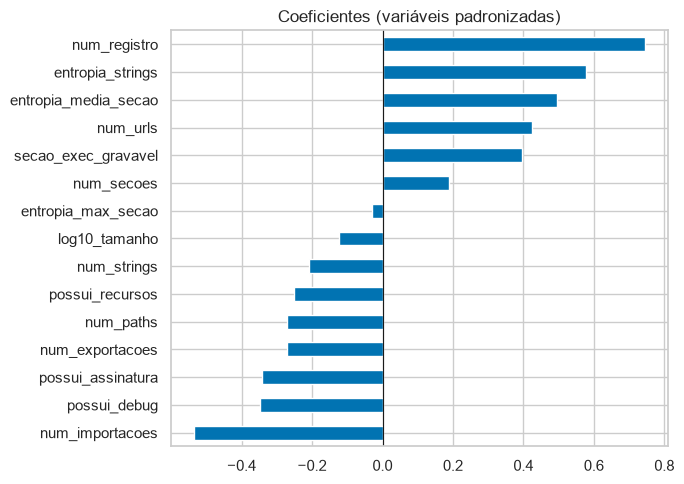

In [5]:
coef = pd.Series(logreg[-1].coef_[0], index=config.FEATURES).sort_values()
coef.plot.barh(figsize=(7, 5), title="Coeficientes (variáveis padronizadas)")
plt.axvline(0, color="k", lw=.8); plt.tight_layout(); plt.show()

Coeficientes positivos aumentam a chance prevista de o arquivo ser malicioso; negativos diminuem.

## 3. Árvore de decisão (profundidade 4, interpretável)

              precision    recall  f1-score   support

      seguro      0.710     0.847     0.773       764
   malicioso      0.772     0.601     0.676       661

    accuracy                          0.733      1425
   macro avg      0.741     0.724     0.724      1425
weighted avg      0.739     0.733     0.728      1425



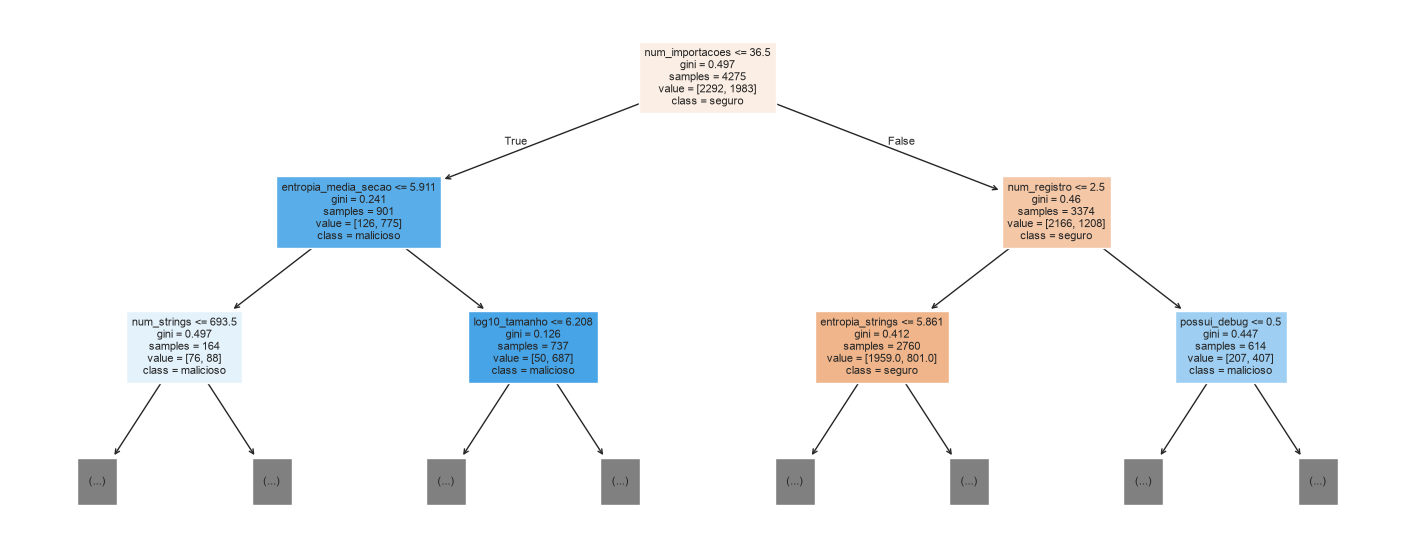

In [6]:
arvore = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_tr, y_tr)
pred_dt = arvore.predict(X_te)
print(classification_report(y_te, pred_dt, target_names=["seguro", "malicioso"], digits=3))
plt.figure(figsize=(18, 7))
plot_tree(arvore, feature_names=config.FEATURES, class_names=["seguro", "malicioso"],
          filled=True, max_depth=2, fontsize=8)
plt.show()

## 4. Resultados

In [7]:
def metricas(y_true, y_pred):
    return {"acurácia": accuracy_score(y_true, y_pred), "precisão": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred)}

resultados = pd.DataFrame({"Linha de base": {"acurácia": base, "precisão": np.nan, "recall": 0.0, "F1": 0.0},
                           "Regressão logística": metricas(y_te, pred_lr),
                           "Árvore de decisão": metricas(y_te, pred_dt)}).T.round(3)
resultados

,acurácia,precisão,recall,F1
Linha de base,0.536,NaN,0.000,0.000
Regressão logística,0.785,0.794,0.725,0.758
Árvore de decisão,0.733,0.772,0.601,0.676


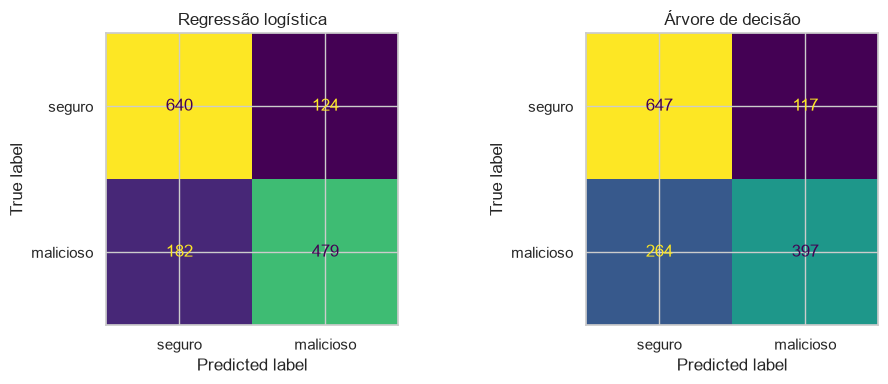

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, p) in zip(axes, [("Regressão logística", pred_lr), ("Árvore de decisão", pred_dt)]):
    ConfusionMatrixDisplay.from_predictions(y_te, p, display_labels=["seguro", "malicioso"], ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout(); plt.show()

> ⚠️ Valores obtidos com a base **sintética** de demonstração. Refaça a interpretação após rodar com a amostra real do EMBER.

**Interpretação:**
- Os dois modelos ficam bem acima da linha de base (acurácia 0,54), então **aprenderam padrões reais** dos dados.
- A regressão logística foi melhor (F1 0,76 contra 0,68). A árvore rasa (profundidade 4) é fácil de ler, mas **deixa passar 40% dos maliciosos** (recall 0,60).
- Nos dois casos o **recall dos maliciosos é menor que a precisão**: o erro mais comum é o **falso negativo** (malware classificado como seguro), que é justamente o erro mais perigoso. Na Avaliação de Modelos (11/11) vamos ajustar o limiar de decisão para tratar disso.

## 5. Exemplo de regressão: prever o tamanho do arquivo

In [9]:
cols_reg = ["num_secoes", "num_importacoes", "num_strings", "num_exportacoes", "possui_recursos"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(df[cols_reg], df["log10_tamanho"], test_size=0.25, random_state=42)
reg = LinearRegression().fit(Xr_tr, yr_tr)
pred_r = reg.predict(Xr_te)
print(f"MAE: {mean_absolute_error(yr_te, pred_r):.3f} (em log10 bytes)")
print(f"R²:  {r2_score(yr_te, pred_r):.3f}")

MAE: 0.464 (em log10 bytes)
R²:  0.047


**Interpretação:** R² ≈ 0,05 quer dizer que essas variáveis **quase não explicam** o tamanho do arquivo, e o erro médio é de ~0,46 em log10 (o tamanho previsto erra, em média, por um fator de ~3). O exemplo serve para praticar as métricas de regressão (MAE e R²) e mostra que **nem toda pergunta pode ser respondida com as variáveis disponíveis**.